In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch

from timesfm3 import TimesFM3Forecaster

np.random.seed(42)
torch.manual_seed(42)

print(f"Pytorch ver: {torch.__version__}")
print(f"CUDA: available: {torch.cuda.is_available()}")

Pytorch ver: 2.11.0+cu128
CUDA: available: True


In [14]:
forecaster = TimesFM3Forecaster.from_pretrained("google/timesfm-3.0-pytorch",per_core_batch_size = 64,)
print(f"TimeFM forecaster loaded successfully on device: {forecaster.device}")

TimeFM forecaster loaded successfully on device: cuda


## test easy sin curve plot

In [15]:
t = np.linspace(0,50,512)
context = np.sin(t).astype(np.float32)

output = forecaster.predict(
    context=context,
    horizon=30
)

print("Forecast shape: ", output.forecast.shape)
print("Forecast first 5 step:\n", output.forecast[:5])

Forecast shape:  (30,)
Forecast first 5 step:
 [-0.16762587 -0.07201765  0.025215    0.12359396  0.21992154]


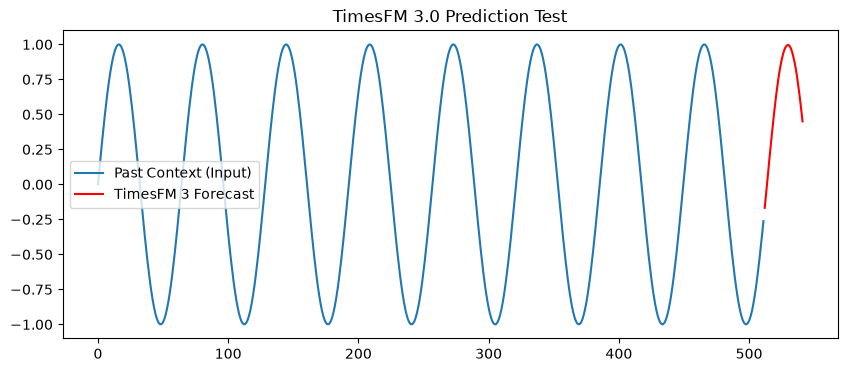

In [16]:
plt.figure(figsize=(10, 4))
plt.plot(range(len(context)), context, label="Past Context (Input)")
plt.plot(range(len(context), len(context) + 30), output.forecast, label="TimesFM 3 Forecast", color="red")
plt.title("TimesFM 3.0 Prediction Test")
plt.legend()
plt.show()